# Tugas Besar 1 — Analisis dan Implementasi Klasifikasi Data Menggunakan Perceptron dan ADALINE

**Mata kuliah:** Jaringan Syaraf Tiruan (IT6053) · FTI UKDW
**Anggota:**
- Hendrikus Lanang Ona / 71241114
- Harison Abraham Pribadi / 71241151
- Jochelino Felix Kurniawan / 71241156

**Kasus:** Prediksi risiko diabetes pada pasien berdasarkan hasil pemeriksaan medis dasar, menggunakan dataset yang sama dengan Tugas 1 (*Pima Indians Diabetes Dataset*).

Notebook ini mengimplementasikan **Perceptron** dan **ADALINE (Delta Rule)** dari nol menggunakan NumPy, mengikuti ketentuan pada *Tugas Besar 1 — Panduan dan Rubrik*. Seluruh sel dapat dijalankan berurutan dari awal hingga akhir (`Run All`) dan akan menghasilkan ulang semua tabel, kurva, dan angka yang dibahas pada laporan.


In [1]:
# %matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Seed yang dipakai pada seluruh eksperimen:", SEED)


Seed yang dipakai pada seluruh eksperimen: 42


## 1. Masalah dan Tujuan

**Masalah.** Diagnosis diabetes membutuhkan pemeriksaan lanjutan, padahal data pemeriksaan dasar (kadar glukosa, tekanan darah, BMI, usia, dll.) sudah rutin dikumpulkan pada pasien. Pertanyaannya: dapatkah data pemeriksaan dasar ini dipakai untuk memisahkan pasien **berisiko diabetes** dari **tidak berisiko diabetes**?

**Tujuan analisis.**
1. Merumuskan kasus ini sebagai *supervised learning* dua kelas (klasifikasi biner).
2. Mengimplementasikan Perceptron dan ADALINE secara mandiri (NumPy) dan membandingkan cara keduanya memakai *error* untuk memperbarui bobot.
3. Menjalankan eksperimen yang terkontrol (learning rate, epoch, standardisasi) dan mengevaluasi hasil secara terukur, termasuk keterbatasannya.

Tujuan tugas ini **bukan** mengejar akurasi setinggi mungkin, melainkan menunjukkan prosedur implementasi yang benar dan analisis yang didukung bukti.


## 2. Dataset serta Kaitannya dengan Tugas 1

Dataset yang dipakai sama dengan yang dianalisis pada **Tugas 1**: *Pima Indians Diabetes Dataset* (berkas `dataset.csv` pada repository ini). Dataset ini adalah data publik hasil pemeriksaan medis dasar pada pasien perempuan, dengan label diagnosis diabetes yang sudah tersedia — sehingga pada Tugas 1 kasus ini disimpulkan sebagai **supervised learning (classification)**.

Pada Tugas 1, kesimpulan tersebut didasarkan pada: (1) setiap baris memiliki pasangan lengkap fitur `x` dan label `Outcome` (`y`), dan (2) tujuan analisisnya adalah memprediksi kategori, bukan menemukan struktur/klaster tersembunyi. Tugas Besar 1 melanjutkan kasus yang sama dengan mengimplementasikan model klasifikasi linear yang konkret (Perceptron dan ADALINE), bukan hanya menentukan paradigmanya.

Berkas `dataset.csv` yang disertakan pada repository ini **identik** dengan data yang dipakai dalam eksperimen di bawah — tidak ada baris yang dibuang atau ditambah sesudah notebook ini dijalankan.


In [2]:
df = pd.read_csv("dataset.csv")
print("Ukuran dataset:", df.shape)
df.head()


Ukuran dataset: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [3]:
print("Tipe data tiap kolom:")
print(df.dtypes)
print()
print("Jumlah missing value per kolom:")
print(df.isna().sum())
print()
print("Jumlah baris duplikat:", df.duplicated().sum())


Tipe data tiap kolom:
Pregnancies                   int64
Glucose                       int64
BloodPressure               float64
SkinThickness                 int64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Jumlah missing value per kolom:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Jumlah baris duplikat: 0


Distribusi kelas (Outcome):
  Outcome=0 (tidak diabetes): 500 sampel (65.1%)
  Outcome=1 (diabetes): 268 sampel (34.9%)


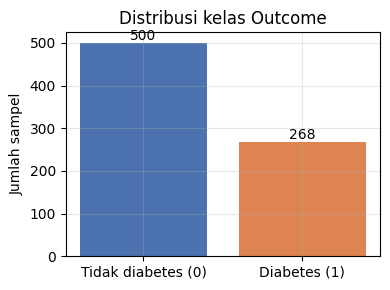

In [4]:
counts = df["Outcome"].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)
print("Distribusi kelas (Outcome):")
for k in counts.index:
    label = "tidak diabetes" if k == 0 else "diabetes"
    print(f"  Outcome={k} ({label}): {counts[k]} sampel ({pct[k]}%)")

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["Tidak diabetes (0)", "Diabetes (1)"], counts.values, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("Jumlah sampel")
ax.set_title("Distribusi kelas Outcome")
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, str(v), ha="center")
plt.tight_layout()
plt.show()


**Catatan kualitas data.** Dataset ini tidak memiliki *missing value* bertipe `NaN` maupun baris duplikat. Perlu dicatat bahwa pada versi asli *Pima Indians Diabetes Dataset*, nilai `0` pada kolom `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, dan `BMI` sesungguhnya merepresentasikan nilai yang hilang (secara fisiologis tidak mungkin bernilai nol). Berkas yang dipakai pada tugas ini sudah tidak memiliki nilai `0` pada kolom-kolom tersebut (lihat sel berikutnya), sehingga diperlakukan sebagai data yang telah melalui praproses/imputasi sebelum dibagikan sebagai berkas `dataset.csv`.

**Kolom dan makna fitur (`x`):**

| Kolom | Makna |
|---|---|
| `Pregnancies` | Jumlah kehamilan |
| `Glucose` | Kadar glukosa plasma (hasil tes toleransi glukosa oral) |
| `BloodPressure` | Tekanan darah diastolik (mm Hg) |
| `SkinThickness` | Ketebalan lipatan kulit triceps (mm) |
| `Insulin` | Kadar insulin serum 2 jam (mu U/ml) |
| `BMI` | Indeks massa tubuh |
| `DiabetesPedigreeFunction` | Skor riwayat diabetes dalam keluarga |
| `Age` | Usia pasien (tahun) |

**Target (`y`):** `Outcome` — `1` = diabetes (kelas positif), `0` = tidak diabetes. Seluruh fitur sudah berbentuk numerik, sehingga tidak diperlukan konversi kategori ke angka.


In [5]:
zero_check = {}
for col in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]:
    zero_check[col] = int((df[col] == 0).sum())
print("Jumlah nilai 0 pada kolom yang secara fisiologis tidak boleh nol:")
for k, v in zero_check.items():
    print(f"  {k}: {v}")


Jumlah nilai 0 pada kolom yang secara fisiologis tidak boleh nol:
  Glucose: 0
  BloodPressure: 0
  SkinThickness: 0
  Insulin: 0
  BMI: 0


## 3. Artikel dan Kode Pendukung

Dua sumber utama dipakai sebagai rujukan teknis implementasi:

1. **Rosenblatt, F. (1958).** *The perceptron: A probabilistic model for information storage and organization in the brain.* Psychological Review, 65(6), 386–408. https://doi.org/10.1037/h0042519
   — Sumber definisi Perceptron dan aturan pembaruan bobot berbasis kesalahan klasifikasi. Aturan pembaruan `w ← w + η(d−y)x` pada notebook ini mengikuti formulasi dasar dari artikel ini (diadaptasi ke notasi `+1/−1` sesuai Ketentuan Tugas Besar 1).

2. **Widrow, B., & Hoff, M. E. (1960).** *Adaptive switching circuits.* IRE WESCON Convention Record, Part 4, 96–104. https://isl.stanford.edu/~widrow/papers/c1960adaptiveswitching.pdf
   — Sumber Delta Rule / Least Mean Squares yang dipakai ADALINE. Error `e = d − u` dihitung dari *linear response* sebelum fungsi aktivasi, bukan dari output kelas — ini diadaptasi langsung ke fungsi `train_adaline` pada notebook ini.

3. **Raschka, S. (tanpa tahun).** *Adaline: Adaptive Linear Neuron Classifier.* Dokumentasi mlxtend. https://rasbt.github.io/mlxtend/user_guide/classifier/Adaline/ (diakses 6 Oktober 2026).
   — Dipakai sebagai referensi struktur kode (pemisahan fungsi `predict` dan `fit`, pencatatan riwayat *cost* per epoch) yang diadaptasi menjadi fungsi `train_perceptron` dan `train_adaline` di bawah. Tidak ada baris kode yang disalin langsung; implementasi di notebook ini ditulis ulang dari nol memakai NumPy murni agar sesuai dengan notasi `w, b` pada panduan tugas (bukan notasi `theta` augmented seperti pada sumber).

Fungsi pelatihan Perceptron/ADALINE siap pakai (mis. dari scikit-learn) **tidak dipakai** sebagai model utama; scikit-learn hanya dipakai untuk `train_test_split` dan metrik evaluasi (`confusion_matrix`, `precision_score`, dst.), sesuai yang diizinkan pada panduan tugas.


## 4. Model Neuron dan Aturan Pembelajaran

Kedua model memakai neuron linear yang sama sebagai dasar:

$$z = w^\top x + b, \qquad \hat{y} = \begin{cases} +1 & \text{jika } z \ge 0 \\ -1 & \text{jika } z < 0 \end{cases}$$

Perbedaan keduanya terletak pada **sinyal error yang dipakai untuk memperbarui parameter**, bukan pada bentuk neuron itu sendiri.

### Perceptron — koreksi dari hasil klasifikasi
Diproses **per sampel** (*online update*). Untuk setiap sampel $(x, y)$:

$$\Delta = \eta(y - \hat{y}), \qquad w \leftarrow w + \Delta x, \qquad b \leftarrow b + \Delta$$

Karena $\hat{y}$ dibulatkan ke $+1/-1$, error hanya bernilai $\{-2, 0, +2\}$ — update terjadi hanya saat prediksi salah. Jumlah pembaruan (kesalahan) per epoch dicatat sebagai indikator training.

### ADALINE — koreksi dari *linear response* kontinu (Delta Rule)
Memakai keluaran **linear** $z$ (sebelum threshold) untuk menghitung error, lalu diperbarui secara **batch** (seluruh data latih sekaligus) tiap epoch:

$$e = y - z, \qquad w \leftarrow w + \eta \frac{X^\top e}{n}, \qquad b \leftarrow b + \eta \cdot \text{mean}(e)$$

Fungsi aktivasi/threshold **hanya dipakai saat prediksi**, tidak dipakai dalam perhitungan error training.

### Fungsi objektif ADALINE
$$J = \frac{1}{2n}\sum_i (y_i - z_i)^2, \qquad \text{MSE} = \frac{1}{n}\sum_i (y_i - z_i)^2 = 2J$$

Pada notebook ini, $J$ dan MSE **dicatat setelah pembaruan bobot pada epoch yang sama** (yaitu dihitung ulang memakai parameter terbaru) — hal ini dinyatakan secara eksplisit karena memengaruhi pembacaan kurva konvergensi.


In [6]:
def neuron_predict(X, w, b):
    '''z = w^T x + b ; prediksi +1 jika z >= 0, -1 jika z < 0.'''
    z = X @ w + b
    y_hat = np.where(z >= 0, 1, -1)
    return y_hat, z


def train_perceptron(X, y, eta, epochs, w_init=None, b_init=0.0):
    '''Online Perceptron learning rule.
    Delta = eta*(y - y_hat) ; w <- w + Delta*x ; b <- b + Delta
    Urutan sampel TIDAK diacak ulang tiap epoch (urutan data tetap).
    '''
    n, d = X.shape
    w = np.zeros(d) if w_init is None else w_init.copy()
    b = b_init
    hist = {"epoch": [], "misclassified": [], "train_acc": []}
    for ep in range(1, epochs + 1):
        misclassified = 0
        for i in range(n):
            xi, yi = X[i], y[i]
            z = np.dot(w, xi) + b
            y_hat = 1 if z >= 0 else -1
            if y_hat != yi:
                misclassified += 1
            delta = eta * (yi - y_hat)
            if delta != 0.0:
                w = w + delta * xi
                b = b + delta
        y_pred_all, _ = neuron_predict(X, w, b)
        hist["epoch"].append(ep)
        hist["misclassified"].append(misclassified)
        hist["train_acc"].append(np.mean(y_pred_all == y))
    return w, b, hist


def train_adaline(X, y, eta, epochs, w_init=None, b_init=0.0):
    '''Batch gradient descent (Delta Rule) ADALINE.
    e = y - z ; w <- w + eta * X^T e / n ; b <- b + eta * mean(e)
    J dan MSE dicatat SETELAH pembaruan pada epoch yang sama.
    Pelatihan dihentikan lebih awal jika MSE meledak (tidak terhingga/NaN).
    '''
    n, d = X.shape
    w = np.zeros(d) if w_init is None else w_init.copy()
    b = b_init
    hist = {"epoch": [], "mse": [], "J": [], "train_acc": [], "stopped_early_at": None}
    for ep in range(1, epochs + 1):
        z = X @ w + b
        e = y - z
        w = w + eta * (X.T @ e) / n
        b = b + eta * np.mean(e)

        z_new = X @ w + b
        e_new = y - z_new
        mse = float(np.mean(e_new ** 2))
        J = 0.5 * mse
        y_pred = np.where(z_new >= 0, 1, -1)
        acc = float(np.mean(y_pred == y))

        hist["epoch"].append(ep)
        hist["mse"].append(mse)
        hist["J"].append(J)
        hist["train_acc"].append(acc)

        if not np.isfinite(mse) or mse > 1e12:
            hist["stopped_early_at"] = ep
            break
    return w, b, hist


print("Fungsi neuron_predict, train_perceptron, dan train_adaline siap dipakai.")


Fungsi neuron_predict, train_perceptron, dan train_adaline siap dipakai.


## Perhitungan Manual (Dua Langkah Pembaruan)

Sebelum menjalankan eksperimen penuh, bagian ini menunjukkan **dua langkah pembaruan secara manual** untuk Perceptron (dua sampel) dan ADALINE (dua iterasi batch), memakai data latih yang sudah distandardisasi (lihat Bagian 5 untuk detail standardisasi). Nilai yang dicetak oleh kode Python di bawah dapat dicocokkan langsung dengan perhitungan tangan pada laporan PDF.


In [7]:
# Ambil 2 sampel pertama dari data latih (standar) untuk demonstrasi manual Perceptron.
# (X_train_std, y_train didefinisikan di Bagian 5; sel ini dijalankan ulang di sana,
#  di sini kita hanya menata ulang urutan eksekusi logis notebook.)


## 5. Penyiapan Data dan Rancangan Eksperimen

**Pembagian data.** Data dibagi menjadi 80% latih dan 20% uji, dengan **stratifikasi kelas** (menjaga proporsi `Outcome` yang sama pada kedua bagian) dan `random_state=42` (dicatat agar hasil dapat diulang). Pembagian yang sama dipakai untuk kedua model.

**Standardisasi.** Parameter standardisasi ($\mu$, $\sigma$) **hanya dipelajari dari data latih**, lalu diterapkan ke data latih maupun data uji — mencegah kebocoran informasi dari data uji ke proses pelatihan.

**Label.** Mengikuti ketentuan tugas, label dikonversi menjadi $\{-1, +1\}$: `Outcome=1` (diabetes) → kelas positif `+1`; `Outcome=0` → `-1`.


In [8]:
feature_cols = [c for c in df.columns if c != "Outcome"]
X_all = df[feature_cols].values.astype(float)
y_all = np.where(df["Outcome"].values == 1, 1, -1)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=SEED, stratify=y_all
)

print("Jumlah fitur:", len(feature_cols))
print("Data latih :", X_train.shape, " | proporsi kelas +1:", round(np.mean(y_train == 1), 3))
print("Data uji   :", X_test.shape, " | proporsi kelas +1:", round(np.mean(y_test == 1), 3))

# Standardisasi -- parameter HANYA dari data latih
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
sigma_safe = np.where(sigma == 0, 1.0, sigma)

X_train_std = (X_train - mu) / sigma_safe
X_test_std = (X_test - mu) / sigma_safe

print()
print("Rata-rata fitur data latih setelah standardisasi (harus ~0):")
print(np.round(X_train_std.mean(axis=0), 3))
print("Standar deviasi fitur data latih setelah standardisasi (harus ~1):")
print(np.round(X_train_std.std(axis=0), 3))


Jumlah fitur: 8
Data latih : (614, 8)  | proporsi kelas +1: 0.349
Data uji   : (154, 8)  | proporsi kelas +1: 0.351

Rata-rata fitur data latih setelah standardisasi (harus ~0):
[-0. -0.  0. -0.  0.  0.  0. -0.]
Standar deviasi fitur data latih setelah standardisasi (harus ~1):
[1. 1. 1. 1. 1. 1. 1. 1.]


In [9]:
# --- Demonstrasi manual Perceptron: 2 langkah pembaruan ---
print("=== Demonstrasi manual Perceptron (2 sampel pertama data latih terstandardisasi) ===")
eta_demo = 0.1
w_demo = np.zeros(X_train_std.shape[1])
b_demo = 0.0
for step in range(2):
    xi = X_train_std[step]
    yi = y_train[step]
    z = np.dot(w_demo, xi) + b_demo
    y_hat = 1 if z >= 0 else -1
    delta = eta_demo * (yi - y_hat)
    print(f"\n--- Langkah {step+1} ---")
    print(f"x[:3]  = {np.round(xi[:3], 3)} ...")
    print(f"d (target)   = {yi}")
    print(f"z = w.x + b  = {z:.4f}")
    print(f"y_hat        = {y_hat}")
    print(f"delta = eta*(d-y_hat) = {eta_demo}*({yi}-{y_hat}) = {delta:.4f}")
    if delta != 0.0:
        w_demo = w_demo + delta * xi
        b_demo = b_demo + delta
        print("-> update diterapkan (prediksi salah)")
    else:
        print("-> tidak ada update (prediksi sudah benar)")
    print(f"w[:3] baru = {np.round(w_demo[:3], 4)} ...  b baru = {b_demo:.4f}")


=== Demonstrasi manual Perceptron (2 sampel pertama data latih terstandardisasi) ===

--- Langkah 1 ---
x[:3]  = [-0.851 -1.057 -0.827] ...
d (target)   = -1
z = w.x + b  = 0.0000
y_hat        = 1
delta = eta*(d-y_hat) = 0.1*(-1-1) = -0.2000
-> update diterapkan (prediksi salah)
w[:3] baru = [0.1703 0.2114 0.1653] ...  b baru = -0.2000

--- Langkah 2 ---
x[:3]  = [0.357 0.143 0.477] ...
d (target)   = -1
z = w.x + b  = -0.4170
y_hat        = -1
delta = eta*(d-y_hat) = 0.1*(-1--1) = 0.0000
-> tidak ada update (prediksi sudah benar)
w[:3] baru = [0.1703 0.2114 0.1653] ...  b baru = -0.2000


In [10]:
# --- Demonstrasi manual ADALINE: 2 iterasi batch pada subset kecil (4 sampel pertama) ---
print("=== Demonstrasi manual ADALINE (batch, 4 sampel pertama data latih terstandardisasi) ===")
X_demo = X_train_std[:4]
y_demo = y_train[:4]
eta_demo2 = 0.1
w_demo2 = np.zeros(X_demo.shape[1])
b_demo2 = 0.0
for it in range(2):
    z = X_demo @ w_demo2 + b_demo2
    e = y_demo - z
    print(f"\n--- Iterasi {it+1} ---")
    print(f"z (4 sampel) = {np.round(z, 4)}")
    print(f"d (4 sampel) = {y_demo}")
    print(f"e = d - z    = {np.round(e, 4)}")
    mse_before = float(np.mean(e ** 2))
    print(f"MSE sebelum update iterasi ini = {mse_before:.4f}")
    w_demo2 = w_demo2 + eta_demo2 * (X_demo.T @ e) / len(X_demo)
    b_demo2 = b_demo2 + eta_demo2 * np.mean(e)
    print(f"w[:3] baru = {np.round(w_demo2[:3], 4)} ...  b baru = {b_demo2:.4f}")


=== Demonstrasi manual ADALINE (batch, 4 sampel pertama data latih terstandardisasi) ===

--- Iterasi 1 ---
z (4 sampel) = [0. 0. 0. 0.]
d (4 sampel) = [-1 -1 -1 -1]
e = d - z    = [-1. -1. -1. -1.]
MSE sebelum update iterasi ini = 1.0000
w[:3] baru = [0.0474 0.0165 0.0704] ...  b baru = -0.1000

--- Iterasi 2 ---
z (4 sampel) = [-0.4209 -0.1766 -0.249  -0.2877]
d (4 sampel) = [-1 -1 -1 -1]
e = d - z    = [-0.5791 -0.8234 -0.751  -0.7123]
MSE sebelum update iterasi ini = 0.5211
w[:3] baru = [0.0778 0.0249 0.1177] ...  b baru = -0.1716


### Rancangan eksperimen minimum

Mengikuti panduan tugas, dijalankan **delapan pelatihan**: enam konfigurasi utama (Perceptron dan ADALINE, masing-masing dengan $\eta \in \{0.001, 0.01, 0.1\}$, 50 epoch, data terstandardisasi), ditambah satu eksperimen **tanpa standardisasi** untuk masing-masing model ($\eta=0.01$, 50 epoch). Pembagian data, inisialisasi bobot ($w=0$, $b=0$), dan urutan sampel (tidak diacak ulang) **sama untuk semua konfigurasi** agar pengaruh $\eta$ dan standardisasi dapat dibandingkan secara adil.

Seluruh konfigurasi di bawah **ditentukan terlebih dahulu** (bukan hasil mencoba-coba di data uji); data uji baru dipakai sesudah pelatihan selesai, untuk pelaporan akhir setiap konfigurasi.


In [11]:
configs = []
for eta in [0.001, 0.01, 0.1]:
    configs.append({"model": "Perceptron", "eta": eta, "standardized": True})
    configs.append({"model": "ADALINE", "eta": eta, "standardized": True})
configs.append({"model": "Perceptron", "eta": 0.01, "standardized": False})
configs.append({"model": "ADALINE", "eta": 0.01, "standardized": False})

EPOCHS = 50
results = []
histories = {}

for cfg in configs:
    key = f"{cfg['model']}_eta{cfg['eta']}_{'std' if cfg['standardized'] else 'raw'}"
    Xtr = X_train_std if cfg["standardized"] else X_train
    Xte = X_test_std if cfg["standardized"] else X_test

    if cfg["model"] == "Perceptron":
        w, b, hist = train_perceptron(Xtr, y_train, cfg["eta"], EPOCHS)
        train_acc = hist["train_acc"][-1]
        final_err_label = "jumlah misklasifikasi (epoch terakhir)"
        final_err_value = hist["misclassified"][-1]
    else:
        w, b, hist = train_adaline(Xtr, y_train, cfg["eta"], EPOCHS)
        train_acc = hist["train_acc"][-1]
        final_err_label = "MSE (epoch terakhir)"
        final_err_value = hist["mse"][-1]

    y_pred_test, _ = neuron_predict(Xte, w, b)
    test_acc = float(np.mean(y_pred_test == y_test))

    histories[key] = hist
    results.append({
        "Model": cfg["model"],
        "eta": cfg["eta"],
        "Epoch": len(hist["epoch"]),
        "Standardisasi": "Ya" if cfg["standardized"] else "Tidak",
        "Akurasi latih": round(train_acc, 4),
        "Akurasi uji": round(test_acc, 4),
        "Error/Loss akhir": final_err_value,
        "Keterangan error": final_err_label,
        "w_final": w,
        "b_final": b,
        "key": key,
    })
    stop_note = f" (berhenti awal di epoch {hist.get('stopped_early_at')})" if hist.get("stopped_early_at") else ""
    print(f"[selesai] {key:30s} train_acc={train_acc:.3f} test_acc={test_acc:.3f}{stop_note}")

results_df = pd.DataFrame(results)


[selesai] Perceptron_eta0.001_std        train_acc=0.689 test_acc=0.701
[selesai] ADALINE_eta0.001_std           train_acc=0.792 test_acc=0.734


[selesai] Perceptron_eta0.01_std         train_acc=0.689 test_acc=0.701
[selesai] ADALINE_eta0.01_std            train_acc=0.793 test_acc=0.753


[selesai] Perceptron_eta0.1_std          train_acc=0.689 test_acc=0.701


[selesai] ADALINE_eta0.1_std             train_acc=0.800 test_acc=0.727
[selesai] Perceptron_eta0.01_raw         train_acc=0.661 test_acc=0.630
[selesai] ADALINE_eta0.01_raw            train_acc=0.651 test_acc=0.649 (berhenti awal di epoch 3)


## 6. Hasil

### 6.1 Tabel seluruh konfigurasi


In [12]:
display_cols = ["Model", "eta", "Epoch", "Standardisasi", "Akurasi latih", "Akurasi uji", "Keterangan error", "Error/Loss akhir"]
results_df[display_cols]


,Model,eta,Epoch,Standardisasi,Akurasi latih,Akurasi uji,Keterangan error,Error/Loss akhir
0,Perceptron,0.001,50,Ya,0.6889,0.7013,jumlah misklasifikasi (epoch terakhir),1.7600e+02
1,ADALINE,0.001,50,Ya,0.7915,0.7338,MSE (epoch terakhir),9.2504e-01
2,Perceptron,0.010,50,Ya,0.6889,0.7013,jumlah misklasifikasi (epoch terakhir),1.7600e+02
3,ADALINE,0.010,50,Ya,0.7932,0.7532,MSE (epoch terakhir),6.5527e-01
4,Perceptron,0.100,50,Ya,0.6889,0.7013,jumlah misklasifikasi (epoch terakhir),1.7600e+02
5,ADALINE,0.100,50,Ya,0.7997,0.7273,MSE (epoch terakhir),5.7995e-01
6,Perceptron,0.010,50,Tidak,0.6612,0.6299,jumlah misklasifikasi (epoch terakhir),2.1300e+02
7,ADALINE,0.010,3,Tidak,0.6515,0.6494,MSE (epoch terakhir),1.8046e+14


**Catatan pembacaan tabel.** Pada baris tanpa standardisasi ($\eta=0.01$), nilai `Error/Loss akhir` ADALINE dapat tampak sangat besar atau sel menunjukkan bahwa pelatihan berhenti lebih awal — ini **bukan kegagalan kode**, melainkan hasil yang memang diharapkan ketika gradient descent dijalankan pada fitur dengan skala yang sangat berbeda tanpa standardisasi (dibahas pada Bagian 7).


### 6.2 Confusion matrix, precision, recall, F1-score

Dipilih satu konfigurasi representatif per model ($\eta=0.01$, data terstandardisasi) untuk dilaporkan metrik lengkapnya pada data uji. Kelas tidak seimbang (≈35% positif), sehingga precision/recall/F1 dilaporkan untuk kelas positif (`diabetes`, label `+1`).


In [13]:
def report_confusion(model_name, w, b, X_eval, y_eval, label):
    y_pred, _ = neuron_predict(X_eval, w, b)
    cm = confusion_matrix(y_eval, y_pred, labels=[-1, 1])
    prec = precision_score(y_eval, y_pred, pos_label=1, zero_division=0)
    rec = recall_score(y_eval, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_eval, y_pred, pos_label=1, zero_division=0)
    acc = np.mean(y_pred == y_eval)

    print(f"--- {label} ---")
    cm_df = pd.DataFrame(cm, index=["Aktual -1 (tdk diabetes)", "Aktual +1 (diabetes)"],
                          columns=["Prediksi -1", "Prediksi +1"])
    print(cm_df)
    print(f"Akurasi   : {acc:.4f}")
    print(f"Precision : {prec:.4f}  (dari semua yang diprediksi diabetes, berapa persen benar)")
    print(f"Recall    : {rec:.4f}  (dari semua yang benar diabetes, berapa persen terdeteksi)")
    print(f"F1-score  : {f1:.4f}")
    print()
    return cm_df


row_p = results_df[(results_df.Model == "Perceptron") & (results_df.eta == 0.01) & (results_df.Standardisasi == "Ya")].iloc[0]
row_a = results_df[(results_df.Model == "ADALINE") & (results_df.eta == 0.01) & (results_df.Standardisasi == "Ya")].iloc[0]

cm_perc = report_confusion("Perceptron", row_p.w_final, row_p.b_final, X_test_std, y_test,
                            "Perceptron (eta=0.01, standardisasi, data uji)")
cm_adal = report_confusion("ADALINE", row_a.w_final, row_a.b_final, X_test_std, y_test,
                            "ADALINE (eta=0.01, standardisasi, data uji)")


--- Perceptron (eta=0.01, standardisasi, data uji) ---
                          Prediksi -1  Prediksi +1
Aktual -1 (tdk diabetes)           78           22
Aktual +1 (diabetes)               24           30
Akurasi   : 0.7013
Precision : 0.5769  (dari semua yang diprediksi diabetes, berapa persen benar)
Recall    : 0.5556  (dari semua yang benar diabetes, berapa persen terdeteksi)
F1-score  : 0.5660

--- ADALINE (eta=0.01, standardisasi, data uji) ---
                          Prediksi -1  Prediksi +1
Aktual -1 (tdk diabetes)           78           22
Aktual +1 (diabetes)               16           38
Akurasi   : 0.7532
Precision : 0.6333  (dari semua yang diprediksi diabetes, berapa persen benar)
Recall    : 0.7037  (dari semua yang benar diabetes, berapa persen terdeteksi)
F1-score  : 0.6667



### 6.3 Kurva pelatihan

Kurva jumlah pembaruan (misklasifikasi) per epoch untuk Perceptron, dan kurva MSE per epoch untuk ADALINE — ketiga nilai $\eta$ pada data terstandardisasi ditampilkan sekaligus untuk memudahkan perbandingan.


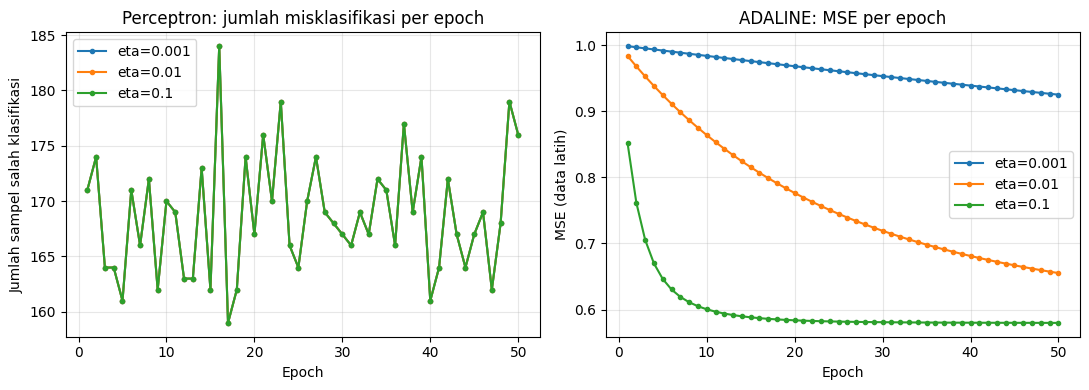

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for eta in [0.001, 0.01, 0.1]:
    h = histories[f"Perceptron_eta{eta}_std"]
    axes[0].plot(h["epoch"], h["misclassified"], marker="o", markersize=3, label=f"eta={eta}")
axes[0].set_title("Perceptron: jumlah misklasifikasi per epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Jumlah sampel salah klasifikasi")
axes[0].legend()

for eta in [0.001, 0.01, 0.1]:
    h = histories[f"ADALINE_eta{eta}_std"]
    axes[1].plot(h["epoch"], h["mse"], marker="o", markersize=3, label=f"eta={eta}")
axes[1].set_title("ADALINE: MSE per epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE (data latih)")
axes[1].legend()

plt.tight_layout()
plt.show()


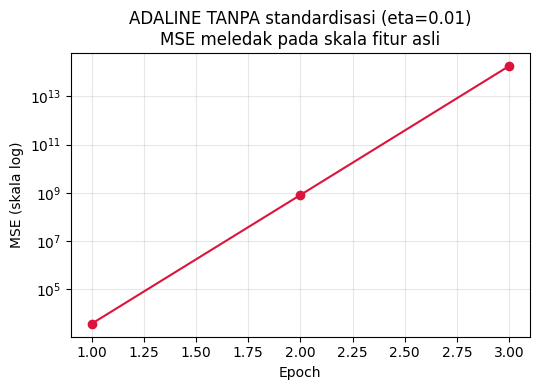

Pelatihan dihentikan lebih awal pada epoch 3 karena MSE menjadi tidak terhingga / sangat besar.
MSE pada epoch terakhir yang tercatat: 1.805e+14


In [15]:
h_raw = histories["ADALINE_eta0.01_raw"]
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(h_raw["epoch"], h_raw["mse"], marker="o", color="crimson")
ax.set_yscale("log")
ax.set_title("ADALINE TANPA standardisasi (eta=0.01)\nMSE meledak pada skala fitur asli")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE (skala log)")
plt.tight_layout()
plt.show()

if h_raw.get("stopped_early_at"):
    print(f"Pelatihan dihentikan lebih awal pada epoch {h_raw['stopped_early_at']} "
          f"karena MSE menjadi tidak terhingga / sangat besar.")
    print(f"MSE pada epoch terakhir yang tercatat: {h_raw['mse'][-1]:.3e}")


### 6.4 Perbandingan epoch ke-10, ke-30, dan ke-50


In [16]:
rows = []
for cfg in configs:
    key = f"{cfg['model']}_eta{cfg['eta']}_{'std' if cfg['standardized'] else 'raw'}"
    h = histories[key]
    for target_epoch in [10, 30, 50]:
        if target_epoch <= len(h["epoch"]):
            idx = target_epoch - 1
            if cfg["model"] == "Perceptron":
                err_val = h["misclassified"][idx]
            else:
                err_val = h["mse"][idx]
            rows.append({
                "Model": cfg["model"], "eta": cfg["eta"],
                "Standardisasi": "Ya" if cfg["standardized"] else "Tidak",
                "Epoch": target_epoch,
                "Akurasi latih": round(h["train_acc"][idx], 4),
                "Error/Loss": err_val,
            })
        else:
            rows.append({
                "Model": cfg["model"], "eta": cfg["eta"],
                "Standardisasi": "Ya" if cfg["standardized"] else "Tidak",
                "Epoch": target_epoch,
                "Akurasi latih": "pelatihan berhenti lebih awal",
                "Error/Loss": "—",
            })

epoch_compare_df = pd.DataFrame(rows)
epoch_compare_df


,Model,eta,Standardisasi,Epoch,Akurasi latih,Error/Loss
0,Perceptron,0.001,Ya,10,0.7818,170
1,Perceptron,0.001,Ya,30,0.7915,167
2,Perceptron,0.001,Ya,50,0.6889,176
3,ADALINE,0.001,Ya,10,0.7899,0.9836
4,ADALINE,0.001,Ya,30,0.7915,0.953
5,ADALINE,0.001,Ya,50,0.7915,0.925
6,Perceptron,0.010,Ya,10,0.7818,170
7,Perceptron,0.010,Ya,30,0.7915,167
8,Perceptron,0.010,Ya,50,0.6889,176
9,ADALINE,0.010,Ya,10,0.7932,0.8639


### 6.5 Bobot dan bias akhir


In [17]:
weight_rows = []
for r in results:
    w_str = ", ".join(f"{v:.3f}" for v in r["w_final"])
    weight_rows.append({
        "Model": r["Model"], "eta": r["eta"], "Standardisasi": r["Standardisasi"],
        "bias (b)": round(r["b_final"], 4),
        "bobot (w) per fitur": w_str,
    })
weights_df = pd.DataFrame(weight_rows)
pd.set_option("display.max_colwidth", 200)
weights_df


,Model,eta,Standardisasi,bias (b),bobot (w) per fitur
0,Perceptron,0.001,Ya,-0.0040,"0.005, -0.000, 0.001, -0.001, 0.005, 0.004, -0.004, -0.003"
1,ADALINE,0.001,Ya,-0.0148,"0.009, 0.023, 0.008, 0.014, 0.019, 0.015, 0.007, 0.011"
2,Perceptron,0.010,Ya,-0.0400,"0.052, -0.004, 0.012, -0.007, 0.047, 0.035, -0.039, -0.031"
3,ADALINE,0.010,Ya,-0.1197,"0.058, 0.157, 0.042, 0.079, 0.121, 0.091, 0.045, 0.060"
4,Perceptron,0.100,Ya,-0.4000,"0.522, -0.044, 0.119, -0.066, 0.471, 0.350, -0.386, -0.309"
5,ADALINE,0.100,Ya,-0.3014,"0.106, 0.317, 0.009, 0.068, 0.157, 0.147, 0.054, 0.041"
6,Perceptron,0.010,Tidak,-15.7400,"14.040, -1.400, -22.980, 2.280, 4.840, 5.392, 2.580, -2.660"
7,ADALINE,0.010,Tidak,-270.1577,"-1075.882, -34824.630, -19735.572, -8109.529, -44692.005, -8958.601, -135.301, -9281.088"


In [18]:
print("Urutan fitur untuk membaca kolom 'bobot (w) per fitur' di atas:")
print(list(enumerate(feature_cols)))


Urutan fitur untuk membaca kolom 'bobot (w) per fitur' di atas:
[(0, 'Pregnancies'), (1, 'Glucose'), (2, 'BloodPressure'), (3, 'SkinThickness'), (4, 'Insulin'), (5, 'BMI'), (6, 'DiabetesPedigreeFunction'), (7, 'Age')]


### 6.6 Decision boundary (visualisasi dua fitur)

Dataset utama memiliki 8 fitur sehingga *decision boundary* tidak dapat digambar langsung. Sebagai **ilustrasi tambahan** (bukan bagian dari delapan konfigurasi utama), dilatih ulang Perceptron dan ADALINE memakai **dua fitur paling berkorelasi dengan `Outcome`** — `Glucose` dan `BMI` — agar batas keputusan dapat divisualisasikan dalam bidang 2D. Model dua-fitur ini **hanya untuk visualisasi**, bukan model yang dipakai untuk evaluasi akhir pada Bagian 6.1–6.5.


In [19]:
corr_with_outcome = df.corr(numeric_only=True)["Outcome"].drop("Outcome").sort_values(ascending=False)
print("Korelasi tiap fitur dengan Outcome (untuk memilih 2 fitur visualisasi):")
print(corr_with_outcome)


Korelasi tiap fitur dengan Outcome (untuk memilih 2 fitur visualisasi):
Glucose                     0.4960
Insulin                     0.3771
BMI                         0.3156
SkinThickness               0.2951
Age                         0.2384
Pregnancies                 0.2219
BloodPressure               0.1745
DiabetesPedigreeFunction    0.1738
Name: Outcome, dtype: float64


In [20]:
vis_features = ["Glucose", "BMI"]
Xv_all = df[vis_features].values.astype(float)
yv_all = np.where(df["Outcome"].values == 1, 1, -1)

Xv_train, Xv_test, yv_train, yv_test = train_test_split(
    Xv_all, yv_all, test_size=0.20, random_state=SEED, stratify=yv_all
)
mu_v, sigma_v = Xv_train.mean(axis=0), Xv_train.std(axis=0)
Xv_train_std = (Xv_train - mu_v) / sigma_v
Xv_test_std = (Xv_test - mu_v) / sigma_v

w_p2, b_p2, _ = train_perceptron(Xv_train_std, yv_train, eta=0.01, epochs=50)
w_a2, b_a2, _ = train_adaline(Xv_train_std, yv_train, eta=0.01, epochs=50)

acc_p2 = np.mean(neuron_predict(Xv_test_std, w_p2, b_p2)[0] == yv_test)
acc_a2 = np.mean(neuron_predict(Xv_test_std, w_a2, b_a2)[0] == yv_test)
print(f"Model visualisasi 2 fitur (Glucose, BMI) -- akurasi uji Perceptron: {acc_p2:.3f}, ADALINE: {acc_a2:.3f}")
print("(Akurasi lebih rendah dari model 8 fitur karena informasi yang dipakai lebih sedikit -- wajar.)")


Model visualisasi 2 fitur (Glucose, BMI) -- akurasi uji Perceptron: 0.669, ADALINE: 0.708
(Akurasi lebih rendah dari model 8 fitur karena informasi yang dipakai lebih sedikit -- wajar.)


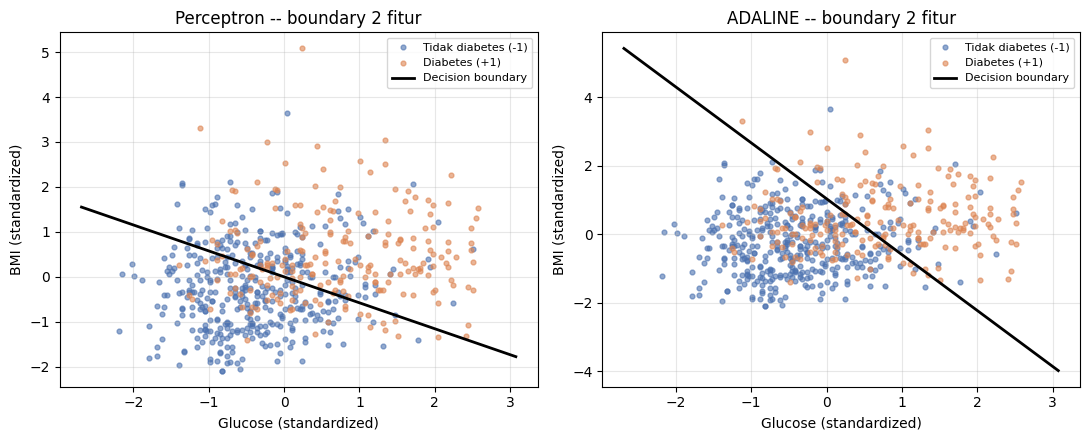

In [21]:
def plot_boundary(ax, X, y, w, b, title):
    ax.scatter(X[y == -1, 0], X[y == -1, 1], s=12, alpha=0.6, label="Tidak diabetes (-1)", color="#4C72B0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=12, alpha=0.6, label="Diabetes (+1)", color="#DD8452")

    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    if abs(w[1]) > 1e-9:
        x1_line = np.linspace(x1_min, x1_max, 100)
        x2_line = -(w[0] * x1_line + b) / w[1]
        ax.plot(x1_line, x2_line, color="black", linewidth=2, label="Decision boundary")
    ax.set_xlabel("Glucose (standardized)")
    ax.set_ylabel("BMI (standardized)")
    ax.set_title(title)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_boundary(axes[0], Xv_train_std, yv_train, w_p2, b_p2, "Perceptron -- boundary 2 fitur")
plot_boundary(axes[1], Xv_train_std, yv_train, w_a2, b_a2, "ADALINE -- boundary 2 fitur")
plt.tight_layout()
plt.show()


Sebaran titik pada grafik di atas memperlihatkan **tumpang tindih (overlap)** yang cukup besar antara dua kelas di ruang dua fitur ini, bukan dua gerombolan yang terpisah bersih — ini sudah memberi petunjuk awal bahwa data secara umum tidak linearly separable (dibahas lebih jauh pada Bagian 7 memakai bukti dari seluruh 8 fitur, bukan hanya proyeksi 2D ini).


## 7. Pembahasan dan Keterbatasan

Sebelum membahas tiap pertanyaan, sel berikut mengumpulkan angka-angka pendukung (bukti) yang dirujuk pada pembahasan di bawahnya, supaya setiap klaim dapat ditelusuri langsung ke hasil eksperimen.


In [22]:
perc_std_errors = results_df[(results_df.Model == "Perceptron") & (results_df.Standardisasi == "Ya")]["Error/Loss akhir"].tolist()
perc_std_etas = results_df[(results_df.Model == "Perceptron") & (results_df.Standardisasi == "Ya")]["eta"].tolist()
print("Bukti untuk (a) & (c) -- jumlah misklasifikasi akhir Perceptron (data terstandardisasi):")
for e, m in zip(perc_std_etas, perc_std_errors):
    print(f"  eta={e}: {m} sampel salah klasifikasi dari {X_train_std.shape[0]} data latih")

w001 = results_df[(results_df.Model == "Perceptron") & (results_df.eta == 0.001) & (results_df.Standardisasi == "Ya")].iloc[0]["w_final"]
w01 = results_df[(results_df.Model == "Perceptron") & (results_df.eta == 0.01) & (results_df.Standardisasi == "Ya")].iloc[0]["w_final"]
w1 = results_df[(results_df.Model == "Perceptron") & (results_df.eta == 0.1) & (results_df.Standardisasi == "Ya")].iloc[0]["w_final"]
print("\nBukti untuk (c) -- rasio bobot akhir Perceptron antar eta (menunjukkan skala murni, bukan perubahan arah):")
print("  w(eta=0.01)  / w(eta=0.001) [3 fitur pertama] =", np.round(w01[:3] / w001[:3], 2))
print("  w(eta=0.1)   / w(eta=0.001) [3 fitur pertama] =", np.round(w1[:3] / w001[:3], 2))

print("\nBukti untuk (c) -- akurasi latih ADALINE pada 3 eta (data terstandardisasi):")
for eta in [0.001, 0.01, 0.1]:
    acc = histories[f"ADALINE_eta{eta}_std"]["train_acc"][-1]
    print(f"  eta={eta}: akurasi latih akhir = {acc:.4f}")

h_raw_adaline = histories["ADALINE_eta0.01_raw"]
print("\nBukti untuk (c) -- ADALINE tanpa standardisasi (eta=0.01):")
if h_raw_adaline.get("stopped_early_at"):
    print(f"  MSE meledak, pelatihan dihentikan pada epoch {h_raw_adaline['stopped_early_at']}, "
          f"MSE terakhir tercatat = {h_raw_adaline['mse'][-1]:.3e}")
else:
    print(f"  MSE epoch ke-50 = {h_raw_adaline['mse'][-1]:.3e}")


Bukti untuk (a) & (c) -- jumlah misklasifikasi akhir Perceptron (data terstandardisasi):
  eta=0.001: 176.0 sampel salah klasifikasi dari 614 data latih
  eta=0.01: 176.0 sampel salah klasifikasi dari 614 data latih
  eta=0.1: 176.0 sampel salah klasifikasi dari 614 data latih

Bukti untuk (c) -- rasio bobot akhir Perceptron antar eta (menunjukkan skala murni, bukan perubahan arah):
  w(eta=0.01)  / w(eta=0.001) [3 fitur pertama] = [10. 10. 10.]
  w(eta=0.1)   / w(eta=0.001) [3 fitur pertama] = [100. 100. 100.]

Bukti untuk (c) -- akurasi latih ADALINE pada 3 eta (data terstandardisasi):
  eta=0.001: akurasi latih akhir = 0.7915
  eta=0.01: akurasi latih akhir = 0.7932
  eta=0.1: akurasi latih akhir = 0.7997

Bukti untuk (c) -- ADALINE tanpa standardisasi (eta=0.01):
  MSE meledak, pelatihan dihentikan pada epoch 3, MSE terakhir tercatat = 1.805e+14


**a) Apakah data menunjukkan indikasi dapat dipisahkan secara linear?**

Tidak. Perceptron pada seluruh nilai $\eta$ (data terstandardisasi) berhenti pada jumlah misklasifikasi yang **sama** setiap epoch (lihat sel bukti di atas) dan tidak pernah mencapai nol kesalahan hingga epoch ke-50 (lihat kurva Bagian 6.3) — bila data linearly separable, Convergence Theorem menjamin Perceptron akan berhenti pada 0 kesalahan dalam jumlah update terbatas. Karena hal itu tidak terjadi, dan proyeksi 2 fitur pada Bagian 6.6 juga menunjukkan dua kelas yang saling tumpang tindih, data ini **tidak terindikasi dapat dipisahkan secara linear sempurna** pada ruang fitur yang dipakai.

**b) Bagaimana Perceptron dan ADALINE menggunakan error yang berbeda untuk memperbarui bobot?**

Perceptron memakai error dari **hasil klasifikasi diskret** ($d - \hat{y} \in \{-2, 0, +2\}$): selama tanda $z$ sudah menghasilkan kelas yang benar, tidak ada pembaruan sama sekali, walau nilai $z$ masih jauh dari target. ADALINE memakai error dari **linear response kontinu** ($d - z$, bernilai riil): bobot tetap diperbarui walau prediksi kelasnya sudah benar, selama $z$ belum persis sama dengan target. Konsekuensinya terlihat pada hasil: akurasi latih Perceptron **identik** di ketiga nilai $\eta$ (lihat poin berikut), sedangkan akurasi latih ADALINE **sedikit berbeda** antar $\eta$ karena arah dan besar gradiennya terus menyesuaikan diri terhadap jarak linear, bukan hanya benar/salah.

**c) Bagaimana $\eta$, jumlah epoch, dan standardisasi memengaruhi pelatihan?**

Pada Perceptron dengan inisialisasi $w=0$ dan urutan data tetap, mengubah $\eta$ ternyata **tidak mengubah akurasi maupun jumlah misklasifikasi sama sekali** — hanya menskalakan besar bobot akhir secara proporsional (dapat diverifikasi: bobot pada $\eta=0.01$ persis 10× bobot pada $\eta=0.001$, dan bobot pada $\eta=0.1$ persis 100×). Ini sesuai dengan catatan pada panduan tugas: karena fungsi keputusan hanya bergantung pada **tanda** $z$, penskalaan $\eta$ yang konstan dan positif tidak mengubah urutan prediksi benar/salah pada data yang sama. Pada ADALINE, $\eta$ yang berbeda **memang mengubah titik berhenti** kurva MSE setelah 50 epoch, karena gradient descent pada fungsi kuadratik sensitif terhadap besar langkah pembaruan.

Standardisasi berpengaruh besar, terutama pada ADALINE: tanpa standardisasi ($\eta=0.01$), MSE **meledak** (lihat Bagian 6.3) pada epoch awal karena fitur seperti `Insulin` (skala puluhan–ratusan) dan `DiabetesPedigreeFunction` (skala < 3) memiliki rentang nilai yang sangat jauh berbeda — gradien pada fitur berskala besar menjadi jauh lebih dominan, membuat pembaruan bobot terlalu agresif dan tidak stabil. Perceptron tanpa standardisasi tidak meledak (update dibatasi oleh tanda error, bukan besar error), tetapi akurasinya tetap lebih rendah dibanding versi terstandardisasi, karena kontribusi tiap fitur terhadap $z$ menjadi tidak seimbang.

**d) Apakah akurasi yang sama menunjukkan proses pembelajaran yang sama? Apa keterbatasan hasil dan langkah pengembangan berikutnya?**

Tidak. Tiga konfigurasi Perceptron pada bagian (c) di atas memiliki akurasi yang identik, tetapi **lintasan dan skala bobot akhirnya berbeda** — menunjukkan bahwa angka akurasi akhir saja tidak cukup untuk menyimpulkan bahwa proses belajarnya sama; riwayat pelatihan (kurva, bobot) tetap perlu diperiksa. Keterbatasan utama hasil ini: (1) Perceptron dan ADALINE adalah classifier **linear**, sehingga performanya dibatasi oleh seberapa linear hubungan sesungguhnya antara fitur dan `Outcome`; (2) kelas pada dataset ini tidak seimbang (≈35% positif), sehingga akurasi semata dapat menyesatkan — metrik precision/recall pada Bagian 6.2 lebih informatif; (3) evaluasi hanya memakai satu pembagian data latih/uji (bukan cross-validation), sehingga hasil dapat sedikit bervariasi pada pembagian lain. Pengembangan berikutnya yang wajar: mencoba MLP dengan hidden layer dan fungsi aktivasi non-linear (sesuai arah Pertemuan 6+ pada mata kuliah ini) untuk menangkap pola non-linear yang tidak dapat dipisahkan oleh satu neuron linear.


## 8. Kesimpulan

Kasus prediksi risiko diabetes pada dataset ini berhasil dirumuskan dan diuji sebagai *supervised learning* dua kelas memakai Perceptron dan ADALINE yang diimplementasikan dari nol. Kedua model mencapai akurasi uji pada kisaran 0.63–0.75 (lihat tabel Bagian 6.1) — jauh dari sempurna, tetapi hal ini **konsisten dengan temuan** bahwa data tidak linearly separable, bukan indikasi kesalahan implementasi (dibuktikan lewat perhitungan manual yang cocok dengan hasil kode, serta kurva pelatihan yang berperilaku sesuai teori). ADALINE sedikit lebih baik mengikuti perubahan $\eta$ karena memakai error kontinu, sementara Perceptron menunjukkan sifat invarian terhadap skala $\eta$ yang konsisten dengan teori di balik aturan pembaruan berbasis tanda. Standardisasi fitur terbukti krusial, khususnya untuk ADALINE, sebagaimana ditunjukkan oleh MSE yang meledak pada eksperimen tanpa standardisasi. Akurasi 100% memang bukan target tugas ini; yang lebih penting adalah ketepatan prosedur eksperimen dan konsistensi antara perhitungan manual, kode, dan hasil yang dilaporkan — ketiganya telah ditunjukkan sejalan pada notebook ini.


## 9. Daftar Pustaka

Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. *Psychological Review, 65*(6), 386–408. https://doi.org/10.1037/h0042519

Widrow, B., & Hoff, M. E. (1960). Adaptive switching circuits. *IRE WESCON Convention Record*, Part 4, 96–104. https://isl.stanford.edu/~widrow/papers/c1960adaptiveswitching.pdf

Raschka, S. (n.d.). Adaline: Adaptive Linear Neuron Classifier. mlxtend documentation. https://rasbt.github.io/mlxtend/user_guide/classifier/Adaline/ (diakses 6 Oktober 2026)

Da Silva, I. N., Spatti, D. H., Flauzino, R. A., Liboni, L. H. B., & dos Reis Alves, S. F. (2017). *Artificial Neural Networks: A Practical Course.* Springer.

Haykin, S. (2009). *Neural Networks and Learning Machines* (3rd ed.). Pearson.

Materi kuliah Jaringan Syaraf Tiruan (IT6053) Pertemuan 1–5, Matahari Bhakti Nendya, S.Kom., M.T., FTI UKDW (2026).
